# XAI Clinic: results walkthrough

**Question.** Can routine clinical measurements detect coronary heart disease, can we *explain* each prediction,
and — the part most projects skip — **would the model still work at a hospital it has never seen?**

**Data.** UCI Heart Disease: four hospitals (Cleveland, Hungarian, Switzerland, VA Long Beach).

> Run `uv run xai-clinic` first. This notebook only *reads* the files in `figures/`, so every number and every
> comment below is generated from your own results. Run from the project folder (`Kernel -> Restart & Run All`).

In [1]:
import os, re, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

pd.set_option("display.max_columns", 30, "display.width", 160)
# find the project root (the folder holding pyproject.toml) so this works from any working directory
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
FIG = ROOT / "figures"

def say(text): display(Markdown(text))

def need(name):
    p = FIG / name
    if not p.exists():
        say(f"⚠️ `{p}` not found. Run `uv run xai-clinic` first.")
        return None
    return p

def table(name, **kw):
    p = need(name)
    if p is None: return None
    d = pd.read_csv(p, **kw); display(d); return d

def img(name, width=720):
    p = need(name)
    if p is not None: display(Image(filename=str(p), width=width))

card = (FIG / "MODEL_CARD.md").read_text(encoding="utf-8") if (FIG / "MODEL_CARD.md").exists() else ""
m = re.search(r"heart-disease detection \((.+?)\)", card)
best_model = m.group(1) if m else "the selected model"
say(f"**Selected model:** {best_model}")

**Selected model:** Gradient Boosting

## 1. The data, and why missingness matters
Each hospital recorded different tests. A missing value here is usually *not random*: it is a fingerprint of
the hospital's workflow. That shapes every later decision.

,cleveland,hungarian,switzerland,va
age,0.0,0.0,0.0,0.0
sex,0.0,0.0,0.0,0.0
cp,0.0,0.0,0.0,0.0
trestbps,0.0,0.0,2.0,29.0
chol,0.0,8.0,100.0,28.0
fbs,0.0,3.0,61.0,4.0
restecg,0.0,0.0,1.0,0.0
thalach,0.0,0.0,1.0,27.0
exang,0.0,0.0,1.0,27.0
oldpeak,0.0,0.0,5.0,28.0


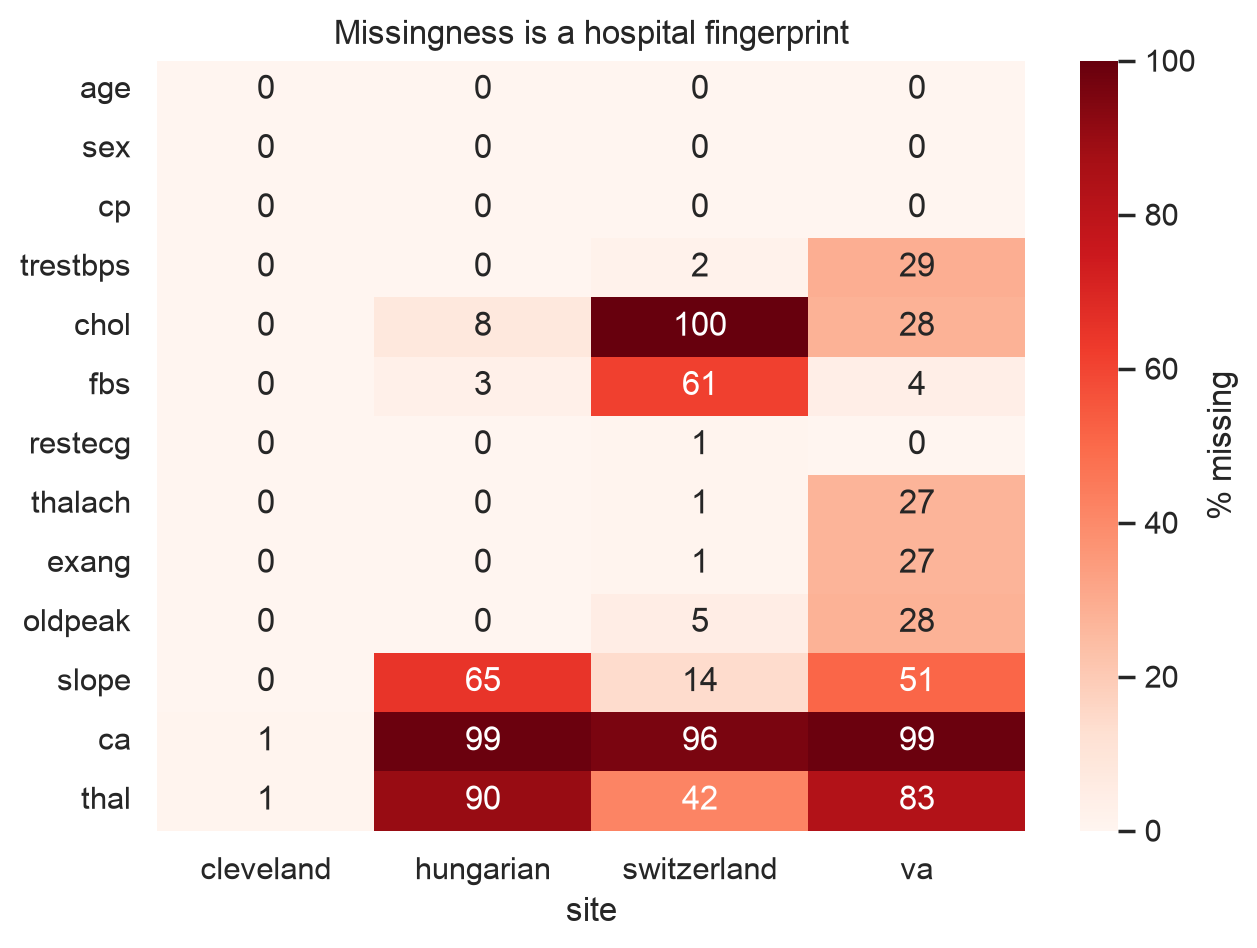

Largest gaps: **chol** at switzerland (100% missing); **ca** at va (99% missing); **ca** at hungarian (99% missing). Features missing in more than 60% of patients were dropped; the rest are imputed *inside* each cross-validation fold so nothing leaks from test data.

In [2]:
miss = table("missing_by_site.csv", index_col=0)
img("01b_missing_by_hospital.png", 560)
if miss is not None:
    worst = miss.stack().sort_values(ascending=False)
    top = [f"**{i[0]}** at {i[1]} ({v:.0f}% missing)" for i, v in worst.head(3).items()]
    say("Largest gaps: " + "; ".join(top) + ". Features missing in more than 60% of patients were dropped; "
        "the rest are imputed *inside* each cross-validation fold so nothing leaks from test data.")

## 2. Is the model comparison fair?
Three models: regularised **logistic regression** (simple baseline), **Random Forest** and **Gradient Boosting**.
Hyper-parameters are tuned *inside* every outer fold (nested CV), and differences are tested with a
corrected paired t-test, because overlapping CV folds make an ordinary t-test too optimistic.

,mean AUC,std,outer folds
Logistic Regression,0.882,0.021,10
Random Forest,0.880,0.022,10
Gradient Boosting,0.885,0.023,10


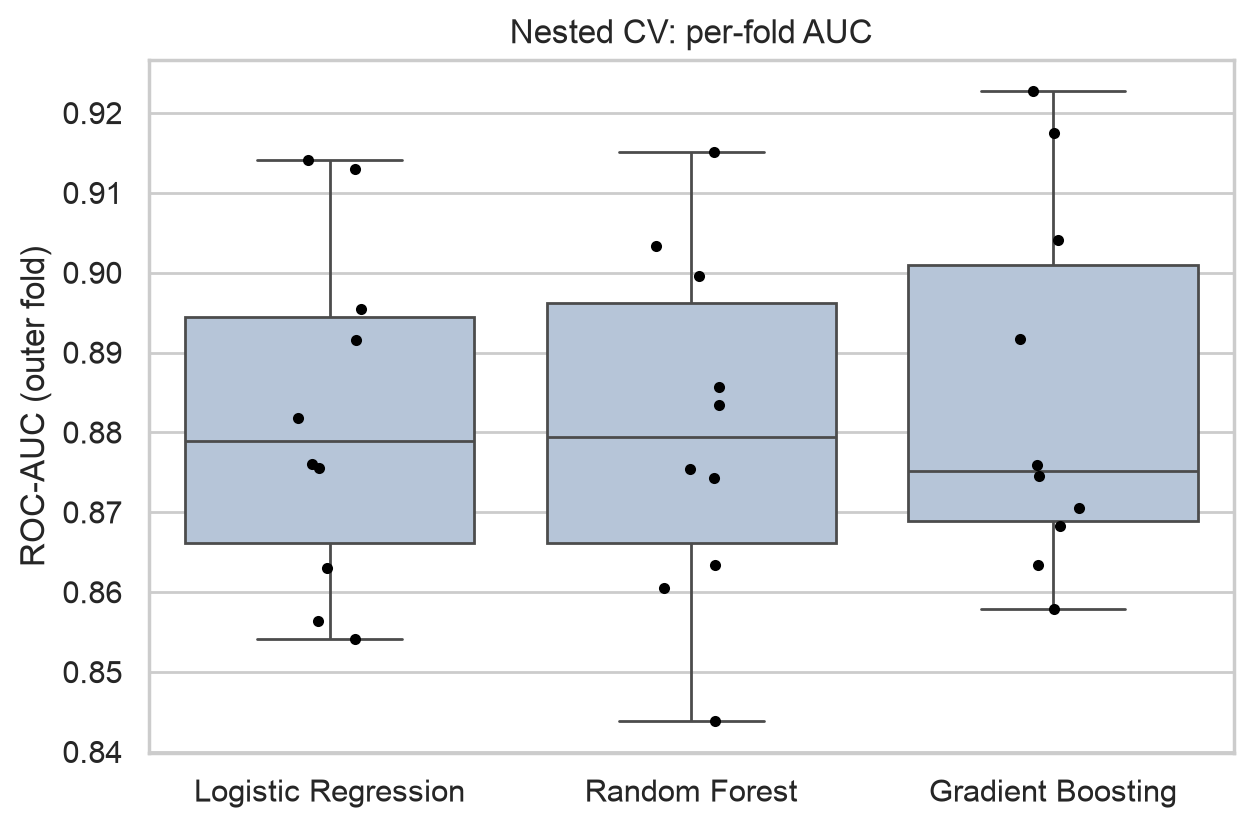

,comparison,mean AUC diff,95% CI,p-value
0,Random Forest - Logistic Regression,-0.0016,"[-0.017, 0.013]",0.811
1,Gradient Boosting - Logistic Regression,0.0026,"[-0.014, 0.019]",0.731
2,Random Forest - Gradient Boosting,-0.0042,"[-0.015, 0.006]",0.392


**Finding:** no pair of models differs significantly (all corrected p > 0.05). The best and worst mean AUC are only 0.005 apart, so the extra complexity of tree ensembles **buys no demonstrable accuracy** here. That is a result, not a failure: it says the signal is in a handful of clinical variables.

In [3]:
p = need("nested_cv_scores.csv")
if p is not None:
    nested = pd.read_csv(p)
    summ = pd.DataFrame({"mean AUC": nested.mean(), "std": nested.std(), "outer folds": len(nested)}).round(3)
    display(summ)
img("03_nested_cv.png", 480)
pairs = table("paired_tests.csv")
if pairs is not None:
    if (pairs["p-value"] > 0.05).all():
        spread = summ["mean AUC"].max() - summ["mean AUC"].min()
        say(f"**Finding:** no pair of models differs significantly (all corrected p > 0.05). The best and worst mean AUC "
            f"are only {spread:.3f} apart, so the extra complexity of tree ensembles **buys no demonstrable accuracy** here. "
            "That is a result, not a failure: it says the signal is in a handful of clinical variables.")
    else:
        say("**Finding:** at least one pair differs significantly (see the p-values above).")

In [4]:
abl = table("ablation.csv")
if abl is not None:
    num = abl.set_index("variant").apply(lambda c: c.str.split(" ").str[0].astype(float))
    prim = [v for v in num.index if "PRIMARY)" in v][0]
    flag = [v for v in num.index if "missing-flags" in v][0]
    d_eng = (num.loc[prim] - num.loc[num.index[0]]).round(3)
    d_flag = (num.loc[flag] - num.loc[prim]).round(3)
    eng_txt = ("barely change" if d_eng.abs().max() < 0.01 else "change")
    say(f"**Ablation reading.** Two engineered features {eng_txt} AUC versus raw features only ({d_eng.to_dict()}). "
        f"Adding missing-flags changes pooled-CV AUC by {d_flag.to_dict()}. "
        "Pooled CV cannot tell a real signal from a hospital shortcut, so section 4 tests it properly.")

,variant,Logistic Regression,Random Forest
0,raw features only,0.878 +/- 0.030,0.874 +/- 0.027
1,raw + 2 engineered (PRIMARY),0.877 +/- 0.030,0.876 +/- 0.028
2,raw + all 4 engineered,0.877 +/- 0.028,0.875 +/- 0.027
3,PRIMARY + missing-flags,0.891 +/- 0.026,0.884 +/- 0.026


**Ablation reading.** Two engineered features barely change AUC versus raw features only ({'Logistic Regression': -0.001, 'Random Forest': 0.002}). Adding missing-flags changes pooled-CV AUC by {'Logistic Regression': 0.014, 'Random Forest': 0.008}. Pooled CV cannot tell a real signal from a hospital shortcut, so section 4 tests it properly.

## 3. Held-out test performance (with uncertainty)
Point estimates alone are misleading on ~180 test patients, so each metric carries a 95% bootstrap interval.

,AUC,Accuracy,Sensitivity,Specificity,Brier
Logistic Regression,"0.880 [0.826, 0.928]","0.793 [0.734, 0.848]","0.824 [0.748, 0.896]","0.756 [0.659, 0.846]",0.143
Random Forest,"0.876 [0.822, 0.923]","0.788 [0.728, 0.848]","0.853 [0.784, 0.923]","0.707 [0.608, 0.800]",0.142
Gradient Boosting,"0.880 [0.829, 0.926]","0.788 [0.728, 0.843]","0.833 [0.764, 0.906]","0.732 [0.635, 0.824]",0.140


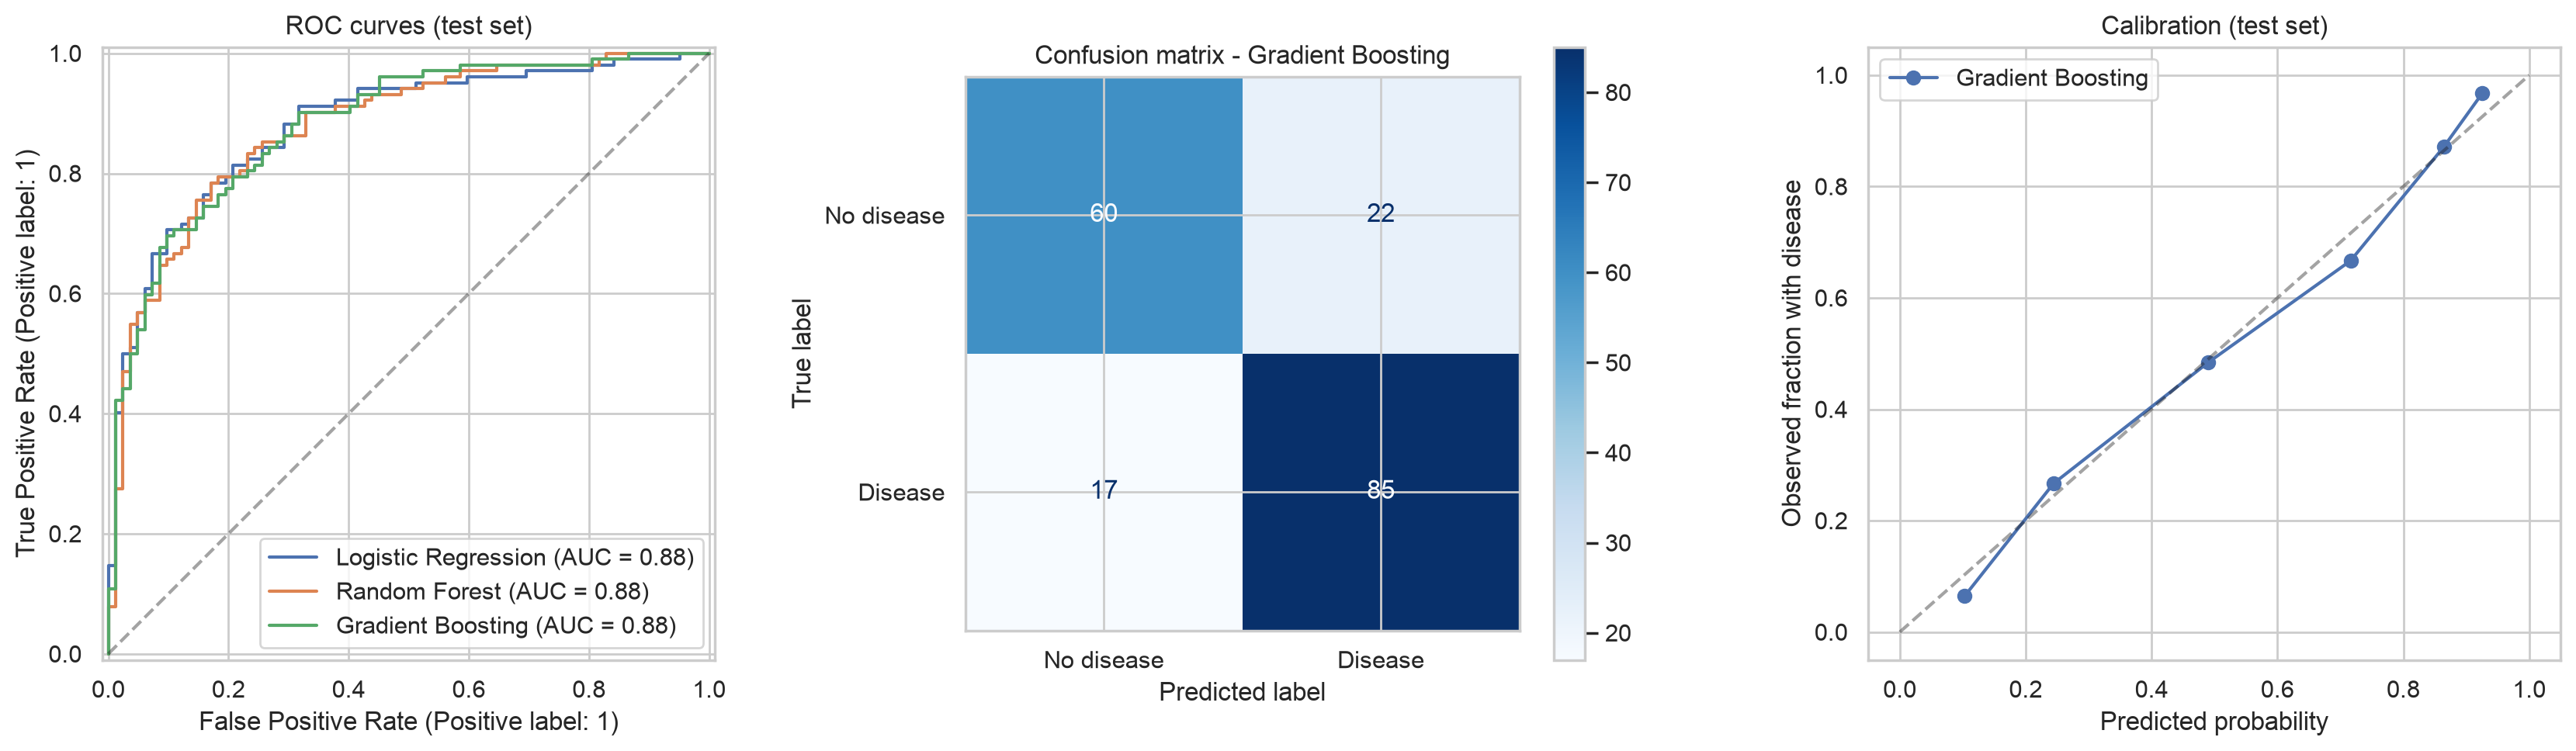

**Best test AUC:** Logistic Regression at 0.880 (95% CI 0.826-0.928). The intervals of all three models overlap heavily, consistent with the statistical tie in section 2. A no-skill model that always predicts the 55% prevalence has Brier ≈ 0.247; Gradient Boosting reaches 0.140 (43% better).

In [5]:
tt = table("test_results_with_CI.csv", index_col=0)
img("04_model_performance.png", 900)
if tt is not None:
    auc = tt["AUC"].str.extract(r"([\d.]+) \[([\d.]+), ([\d.]+)\]").astype(float)
    auc.columns = ["AUC", "lo", "hi"]
    b = auc["AUC"].idxmax()
    sub = pd.read_csv(FIG / "subgroup_performance.csv") if (FIG / "subgroup_performance.csv").exists() else None
    extra = ""
    if sub is not None:
        prev = float(sub.loc[0, "disease rate"]); ref = prev * (1 - prev)
        extra = (f" A no-skill model that always predicts the {prev:.0%} prevalence has Brier ≈ {ref:.3f}; "
                 f"{tt['Brier'].idxmin()} reaches {tt['Brier'].min():.3f} "
                 f"({1 - tt['Brier'].min() / ref:.0%} better).")
    say(f"**Best test AUC:** {b} at {auc.loc[b, 'AUC']:.3f} (95% CI {auc.loc[b, 'lo']:.3f}-{auc.loc[b, 'hi']:.3f}). "
        "The intervals of all three models overlap heavily, consistent with the statistical tie in section 2." + extra)

## 4. Would it work at a hospital it has never seen?
**Leave-one-hospital-out:** train on three hospitals (re-tuning each time), test on the fourth. Done twice:
without and with *missing-value flags*, to test whether "which tests were recorded" is a transferable signal
or merely identifies the hospital. (Switzerland is skipped: only ~7% of its patients are disease-free, so AUC is meaningless.)

In [6]:
lo = pd.read_csv(FIG / "leave_one_hospital_out.csv") if need("leave_one_hospital_out.csv") else None
if lo is not None:
    piv = lo.pivot_table(index="hospital", columns=["model", "missing-flags"], values="AUC")
    display(piv.round(3))
    mean_flag = lo.groupby("missing-flags")["AUC"].mean()
    cells = lo.pivot_table(index=["hospital", "model"], columns="missing-flags", values="AUC")
    gain = mean_flag["yes"] - mean_flag["no"]; nb_ = int((cells["yes"] > cells["no"]).sum())
    weakest = lo[lo["missing-flags"] == "no"].groupby("hospital")["AUC"].mean().sort_values()
    say(f"**Transfer:** mean AUC at an unseen hospital is {mean_flag['no']:.3f} without flags and {mean_flag['yes']:.3f} with flags "
        f"({gain:+.3f}; better in {nb_}/{len(cells)} model-hospital cells). "
        + ("Missingness carries **transferable** signal (workflow and hospital-level baseline differences), so it is not only a shortcut; "
           "the hospital-agnostic model is kept as primary for deployability, and the flagged version is reported as a sensitivity result. "
           if gain > 0.01 else "The gain from flags is negligible, so the pooled-CV improvement was mostly a hospital shortcut. ")
        + f"The hardest hospital to generalise to is **{weakest.index[0]}** (mean AUC {weakest.iloc[0]:.3f}), "
          f"the easiest is **{weakest.index[-1]}** ({weakest.iloc[-1]:.3f}).")

model         Gradient Boosting        Logistic Regression        Random Forest       
missing-flags                no    yes                  no    yes            no    yes
hospital                                                                              
cleveland                 0.841  0.850               0.826  0.886         0.840  0.869
hungarian                 0.852  0.882               0.876  0.896         0.851  0.882
va                        0.706  0.711               0.729  0.737         0.698  0.719

**Transfer:** mean AUC at an unseen hospital is 0.802 without flags and 0.826 with flags (+0.024; better in 9/9 model-hospital cells). Missingness carries **transferable** signal (workflow and hospital-level baseline differences), so it is not only a shortcut; the hospital-agnostic model is kept as primary for deployability, and the flagged version is reported as a sensitivity result. The hardest hospital to generalise to is **va** (mean AUC 0.711), the easiest is **hungarian** (0.860).

### Calibration drift
AUC measures *ranking*; a risk score also needs the **probabilities** to be right. A model trained on pooled data
tends to predict the pooled prevalence everywhere.

,hospital,actual_prev,mean_pred,Brier
2,cleveland,0.46,0.55,0.171
8,hungarian,0.36,0.47,0.163
14,va,0.74,0.65,0.197


**Calibration-in-the-large:** cleveland: actual 46% vs predicted 55% (+9%); hungarian: actual 36% vs predicted 47% (+11%); va: actual 74% vs predicted 65% (-9%). In every hospital the predicted risk is pulled toward the pooled prevalence (55%), so absolute risk should not be carried from one hospital to another unadjusted.

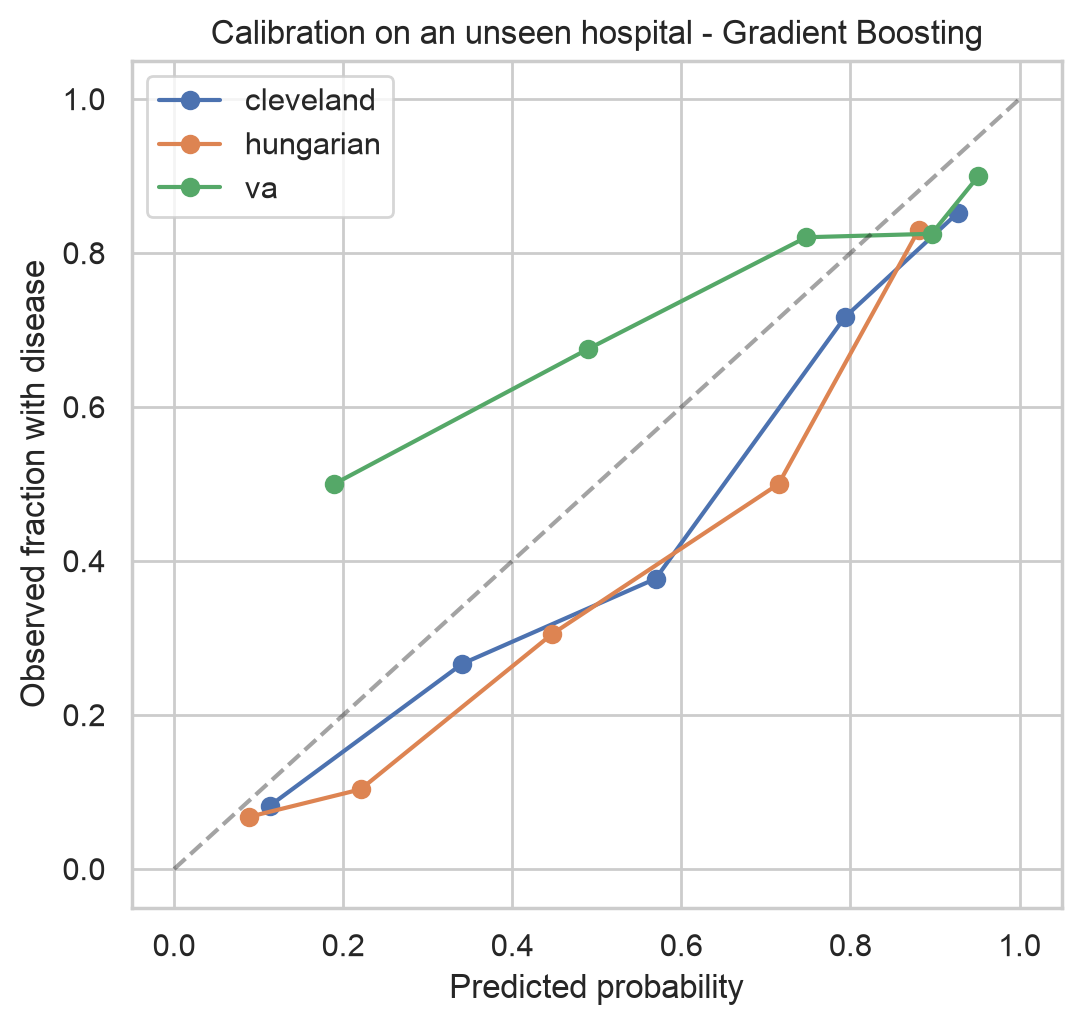

,hospital,Brier before,Brier after,improvement
0,cleveland,0.172,0.165,4%
1,hungarian,0.165,0.151,8%
2,va,0.200,0.177,12%


**Local recalibration** (re-fit intercept and slope using only 30% of the new hospital's patients) lowers Brier score by 8% on average. AUC is unchanged by design: recalibration fixes the *probabilities*, not the *ranking*, so what remains is mostly the limit of the features themselves.

In [7]:
if lo is not None:
    cal = lo[(lo.model == best_model) & (lo["missing-flags"] == "no")][["hospital", "actual_prev", "mean_pred", "Brier"]]
    display(cal)
    cal = cal.assign(gap=(cal.mean_pred - cal.actual_prev).round(2))
    sg0 = pd.read_csv(FIG / "subgroup_performance.csv")
    pooled = float(sg0.loc[0, "disease rate"])
    toward = ((cal.mean_pred - cal.actual_prev) * (pooled - cal.actual_prev) > 0).all()
    say("**Calibration-in-the-large:** " + "; ".join(
        f"{r.hospital}: actual {r.actual_prev:.0%} vs predicted {r.mean_pred:.0%} ({r.gap:+.0%})" for r in cal.itertuples())
        + (f". In every hospital the predicted risk is pulled toward the pooled prevalence ({pooled:.0%}), so absolute risk "
           "should not be carried from one hospital to another unadjusted." if toward else
           ". Predicted risk does not match local prevalence, so absolute risk should not be carried between hospitals unadjusted."))
img("06_calibration_by_hospital.png", 460)
rc = table("local_recalibration.csv")
if rc is not None:
    gain_rc = (1 - rc["Brier after"] / rc["Brier before"]).mean()
    say(f"**Local recalibration** (re-fit intercept and slope using only 30% of the new hospital's patients) lowers Brier score by "
        f"{gain_rc:.0%} on average. AUC is unchanged by design: recalibration fixes the *probabilities*, not the *ranking*, "
        "so what remains is mostly the limit of the features themselves.")

## 5. Who does it work for? Subgroup audit
Out-of-fold predictions on all patients, split by sex, age, hospital and record completeness.

In [8]:
sg = table("subgroup_performance.csv")
if sg is not None:
    s2 = sg.assign(AUCn=pd.to_numeric(sg["AUC"], errors="coerce")).dropna(subset=["AUCn"])
    s2 = s2[s2.subgroup != "all patients"].sort_values("AUCn")
    lows = s2.head(2)
    overall = float(sg.loc[0, "disease rate"])
    say("**Weakest subgroups:** " + "; ".join(
        f"{r.subgroup} (AUC {r.AUCn:.2f}, n={r.n}, disease rate {float(r._3):.0%} vs {overall:.0%} overall)" for r in lows.itertuples())
        + ". Groups whose base rate is very high or very low are harder to rank ('spectrum effect'), so a lower AUC there is expected, "
          "not necessarily a bug. Subgroups marked n/a have too few cases of one class to estimate AUC.")

,subgroup,n,disease rate,AUC
0,all patients,918,0.55,0.879
1,female,193,0.26,0.856
2,male,725,0.63,0.859
3,age < 50,291,0.38,0.898
4,age 50-59,374,0.57,0.866
5,age 60+,253,0.73,0.807
6,hospital: cleveland,303,0.46,0.886
7,hospital: hungarian,293,0.36,0.877
8,hospital: switzerland,123,0.93,n/a (too few)
9,hospital: va,199,0.74,0.72


**Weakest subgroups:** hospital: va (AUC 0.72, n=199, disease rate 74% vs 55% overall); sparse records (3+ core values missing) (AUC 0.73, n=55, disease rate 64% vs 55% overall). Groups whose base rate is very high or very low are harder to rank ('spectrum effect'), so a lower AUC there is expected, not necessarily a bug. Subgroups marked n/a have too few cases of one class to estimate AUC.

## 6. From a model to a decision (business view)
The assumptions are stated, not hidden: the **cost of a missed patient relative to a false alarm** and the
**prevalence in the population you would screen** (the training data is ~55% diseased; real screening is far lower, which collapses PPV).

**Assumptions used:** per 1,000 patients at 10% prevalence; missed case = 5x false alarm

,operating point,threshold,sensitivity,specificity,flagged /1000,cases caught,cases missed,false alarms,PPV,NPV,cost /1000
0,default (0.50),0.5,0.833,0.732,325,83.3,16.7,241,0.257,0.9753,325
1,90%-sensitivity,0.4,0.902,0.683,376,90.2,9.8,285,0.240,0.9843,334
2,cost-optimal,0.7,0.696,0.902,157,69.6,30.4,88,0.442,0.9639,240


At these assumptions the cheapest operating point is **cost-optimal** (threshold 0.7): it catches 69.6 and misses 30.4 true cases per 1,000 patients, with 88 false alarms (PPV 44%). Change them with `--cost-ratio` and `--prevalence` when running `uv run xai-clinic`.

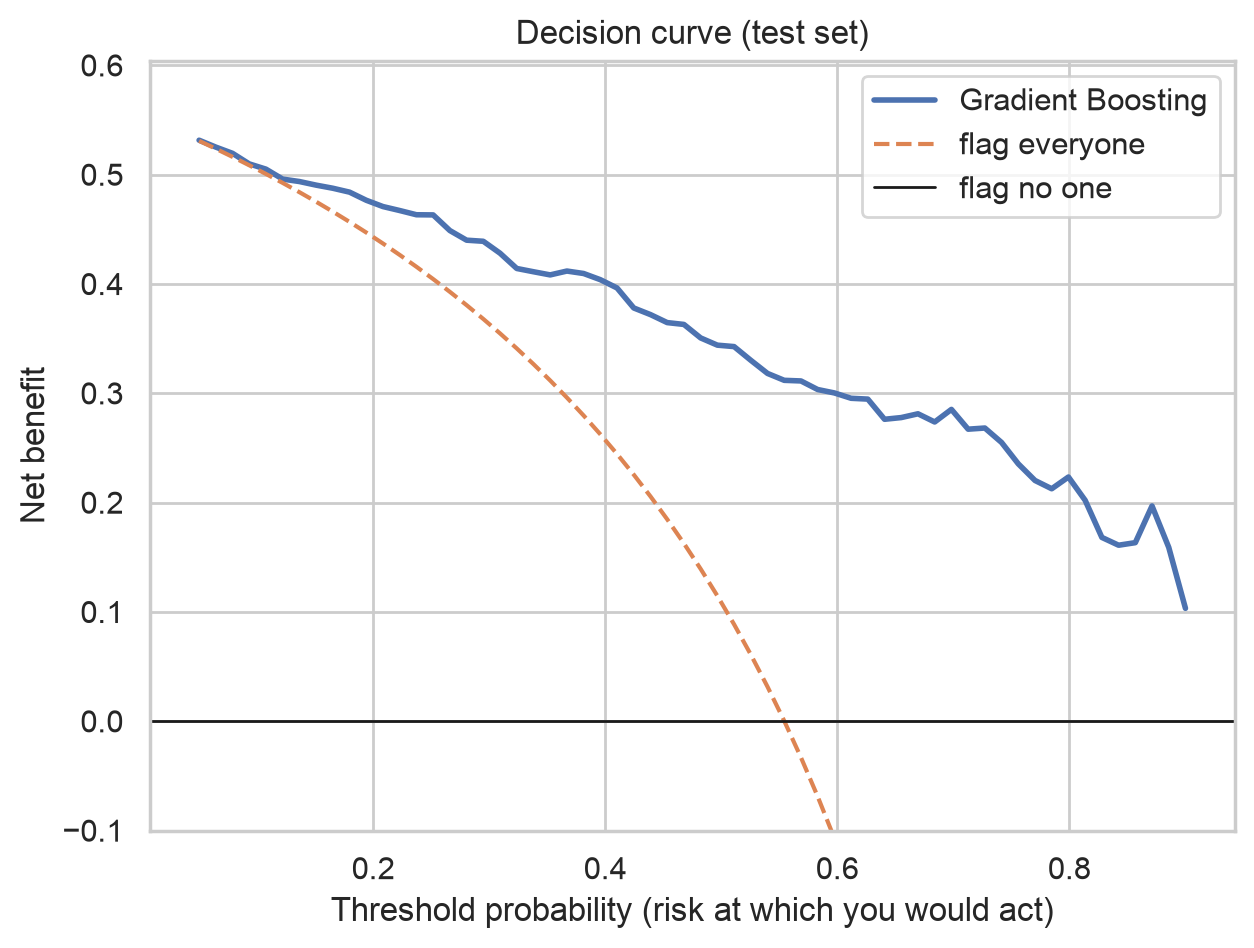

The **decision curve** shows net benefit versus 'flag everyone' and 'flag no one'; the model is useful wherever its curve is above both.

,patients,observed_rate,mean_predicted
tier,,,
Low,268,0.108,0.147
Moderate,257,0.525,0.514
High,393,0.875,0.854


**Risk tiers:** observed disease rate by tier is Low 11%, Moderate 52%, High 88%. It rises monotonically and stays within 4% of the mean predicted risk, so the tiers are a usable summary (in the pooled data).

In [9]:
assume = re.search(r"## Operating points \((.+?)\)", card)
say("**Assumptions used:** " + (assume.group(1) if assume else "see MODEL_CARD.md"))
ops = table("operating_points.csv")
if ops is not None:
    cheapest = ops.loc[ops["cost /1000"].idxmin()]
    say(f"At these assumptions the cheapest operating point is **{cheapest['operating point']}** (threshold {cheapest['threshold']}): "
        f"it catches {cheapest['cases caught']} and misses {cheapest['cases missed']} true cases per 1,000 patients, with "
        f"{cheapest['false alarms']} false alarms (PPV {cheapest['PPV']:.0%}). Change them with `--cost-ratio` and `--prevalence` when running `uv run xai-clinic`.")
img("05_decision_curve.png", 460)
say("The **decision curve** shows net benefit versus 'flag everyone' and 'flag no one'; the model is useful wherever its curve is above both.")
tiers = table("risk_tiers.csv", index_col=0)
if tiers is not None:
    t2 = tiers.reindex([i for i in ["Low", "Moderate", "High"] if i in tiers.index])
    mono = t2["observed_rate"].is_monotonic_increasing
    gap = (t2["observed_rate"] - t2["mean_predicted"]).abs().max()
    say(f"**Risk tiers:** observed disease rate by tier is {', '.join(f'{i} {v:.0%}' for i, v in t2['observed_rate'].items())}. "
        + ("It rises monotonically and " if mono else "It does NOT rise monotonically, and ")
        + (f"stays within {gap:.0%} of the mean predicted risk, so the tiers are a usable summary (in the pooled data)."
           if gap < 0.10 else f"differs from the mean predicted risk by up to {gap:.0%}, so treat the tiers cautiously."))

## 7. Explainability (SHAP)
**Global:** which variables drive predictions, and in which direction. **Agreement:** do three different models tell the same story?

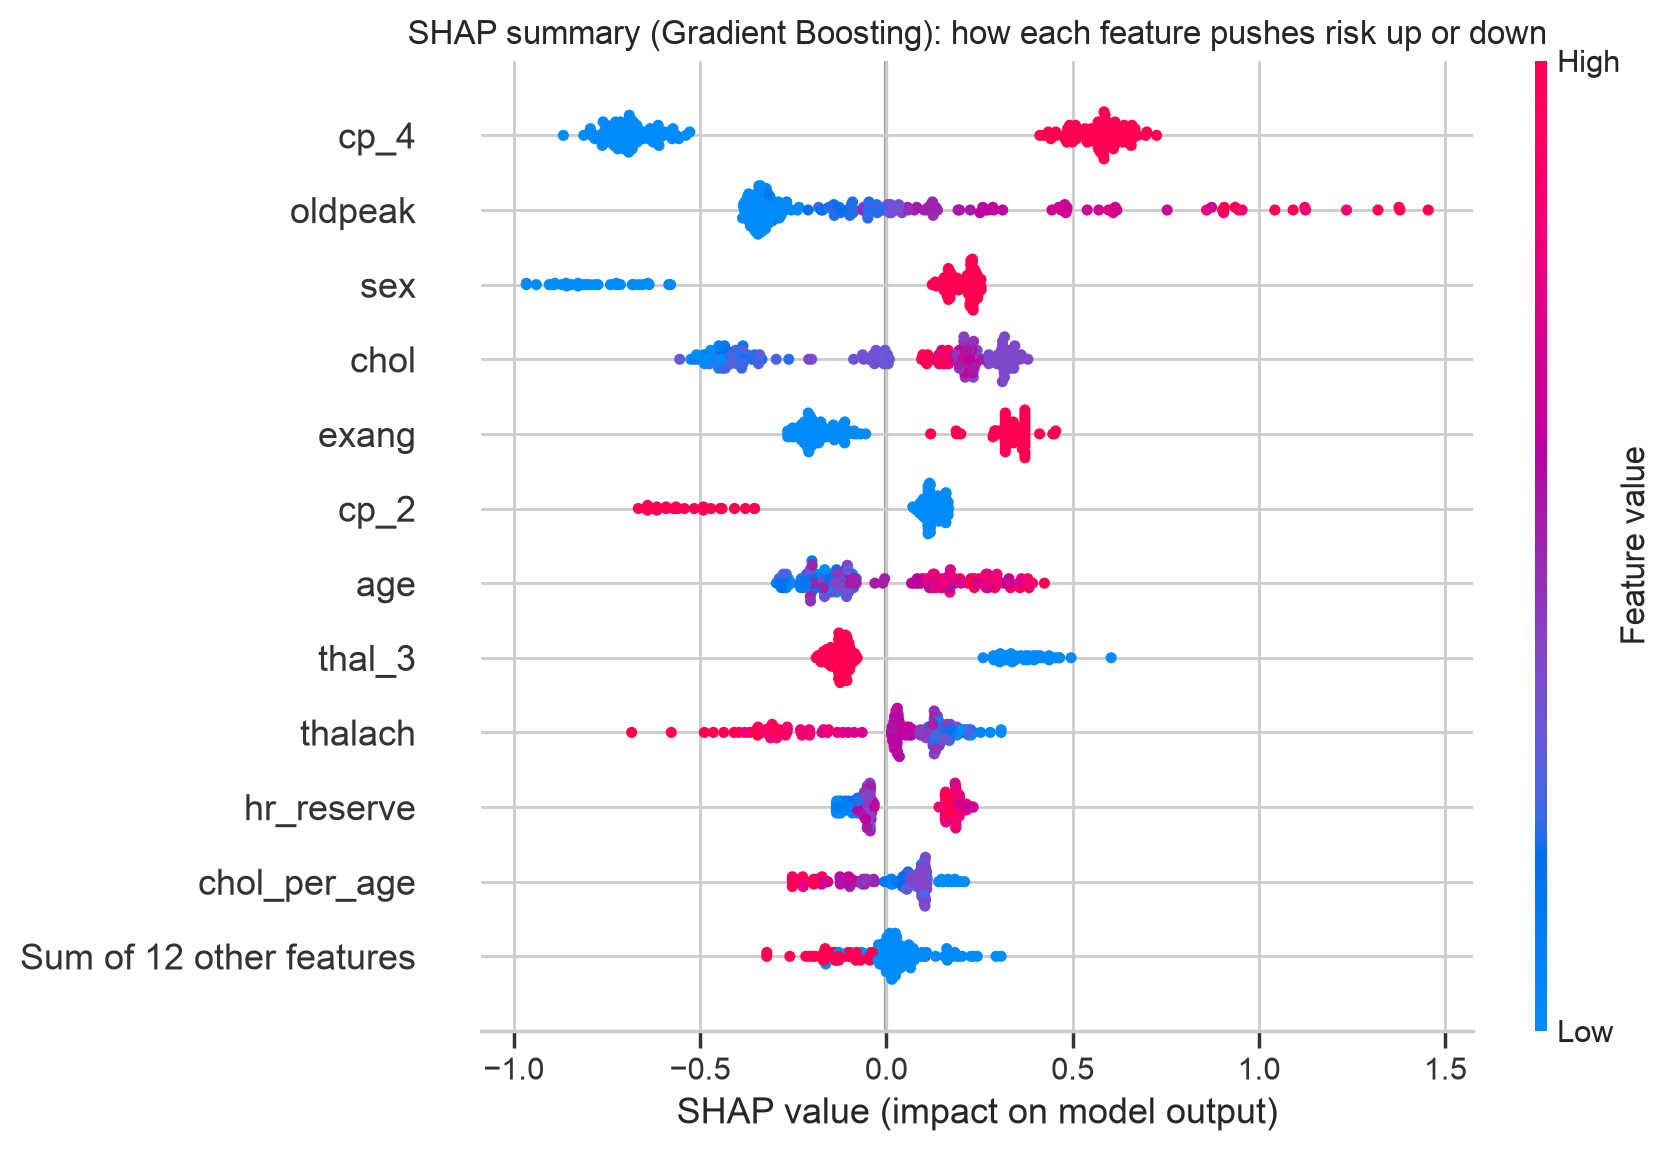

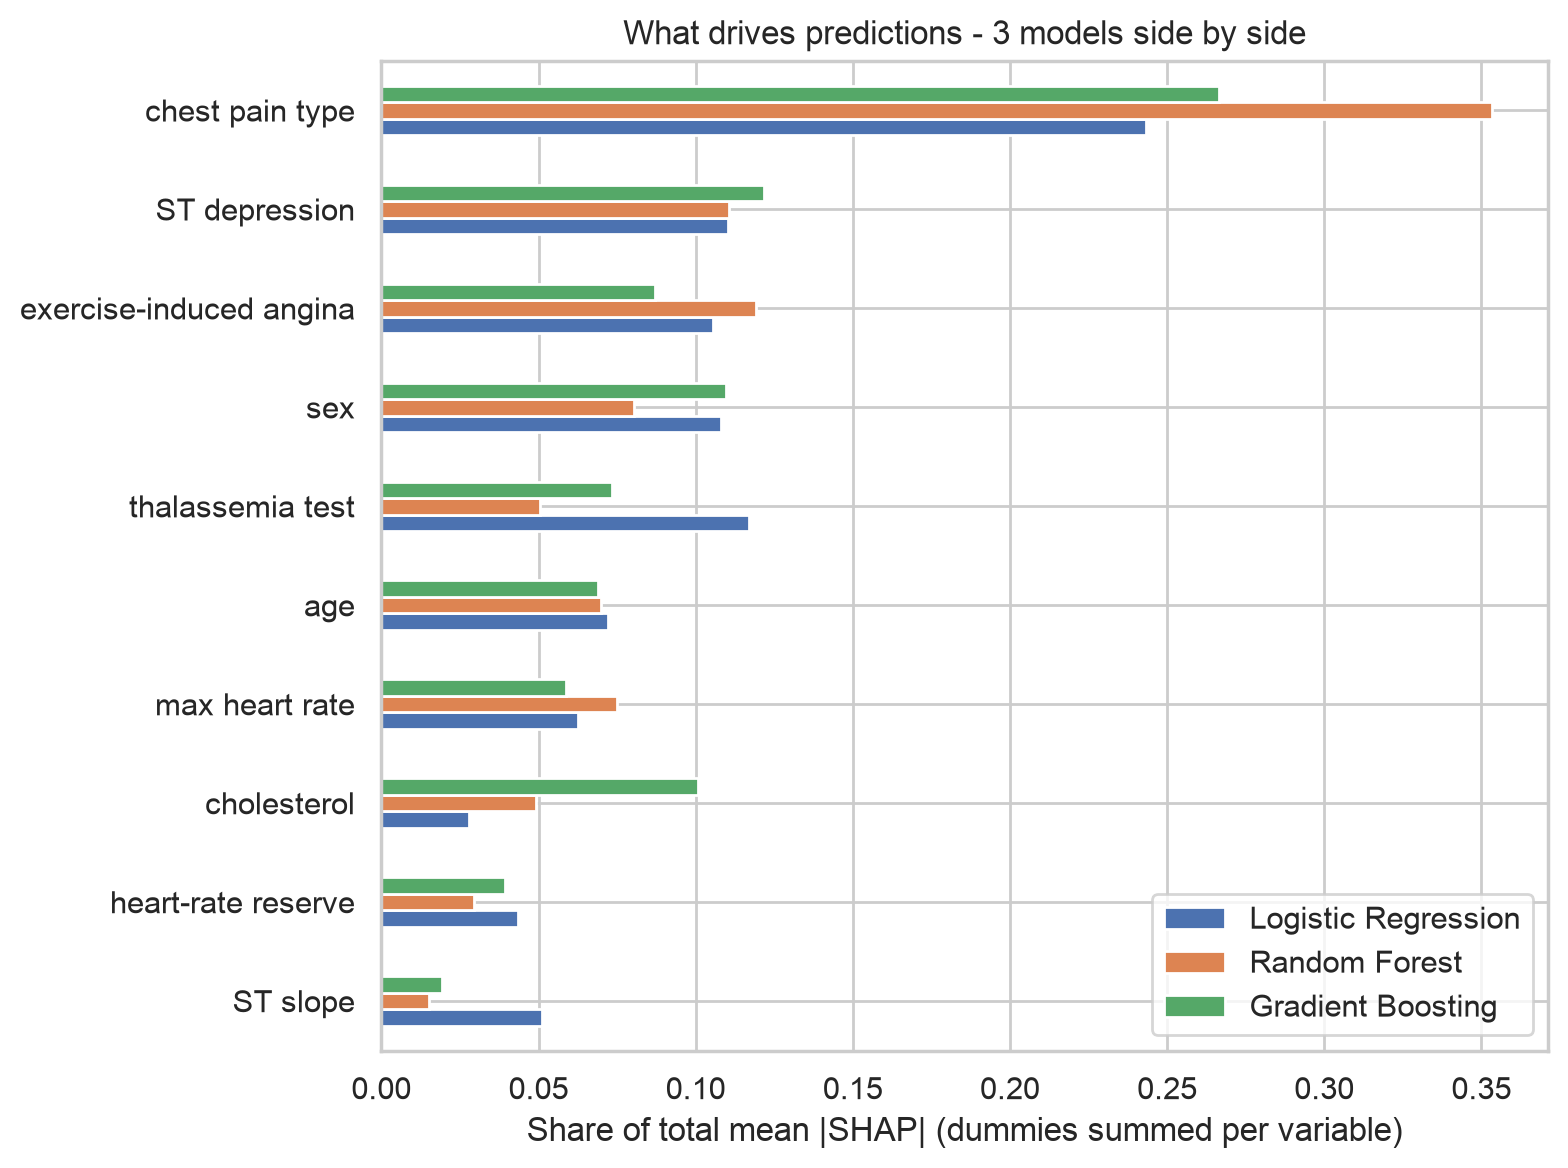

,Logistic Regression,Random Forest,Gradient Boosting
Logistic Regression,1.00,0.81,0.76
Random Forest,0.81,1.00,0.92
Gradient Boosting,0.76,0.92,1.00


**Agreement:** rank correlation of SHAP importance between models ranges 0.76-0.92. Agreement is moderate: treat the *top* variables as robust and the order of the minor ones as model-specific.

,Logistic Regression,Random Forest,Gradient Boosting
chest pain type,0.2432,0.3535,0.2666
ST depression,0.1104,0.1107,0.1218
sex,0.1082,0.0805,0.1096
cholesterol,0.0277,0.0493,0.1006
exercise-induced angina,0.1054,0.1193,0.0872
thalassemia test,0.1169,0.0505,0.0733
age,0.0721,0.0698,0.0688
max heart rate,0.0626,0.0751,0.0587
heart-rate reserve,0.0434,0.0296,0.0394
cholesterol / age,0.0015,0.0261,0.0391


**Caveats a reviewer expects you to state:** SHAP explains what the *model* relies on, not what *causes* disease. Asymptomatic chest pain ranks high largely because of how patients were referred for testing (referral bias). Dummy variables are summed back to their clinical variable, so 'chest pain type' is one bar.

In [10]:
img("08_shap_beeswarm.png", 760)
img("07_shap_model_agreement.png", 620)
rho = table("shap_rank_agreement.csv", index_col=0)
if rho is not None:
    v = rho.values[np.triu_indices(len(rho), 1)]
    say(f"**Agreement:** rank correlation of SHAP importance between models ranges {v.min():.2f}-{v.max():.2f}. "
        + ("Strong agreement makes the explanations more credible than any single model's."
           if v.min() > 0.8 else "Agreement is moderate: treat the *top* variables as robust and the order of the minor ones as model-specific."))
imp = table("shap_importance_grouped.csv", index_col=0)
say("**Caveats a reviewer expects you to state:** SHAP explains what the *model* relies on, not what *causes* disease. "
    "Asymptomatic chest pain ranks high largely because of how patients were referred for testing (referral bias). "
    "Dummy variables are summed back to their clinical variable, so 'chest pain type' is one bar.")

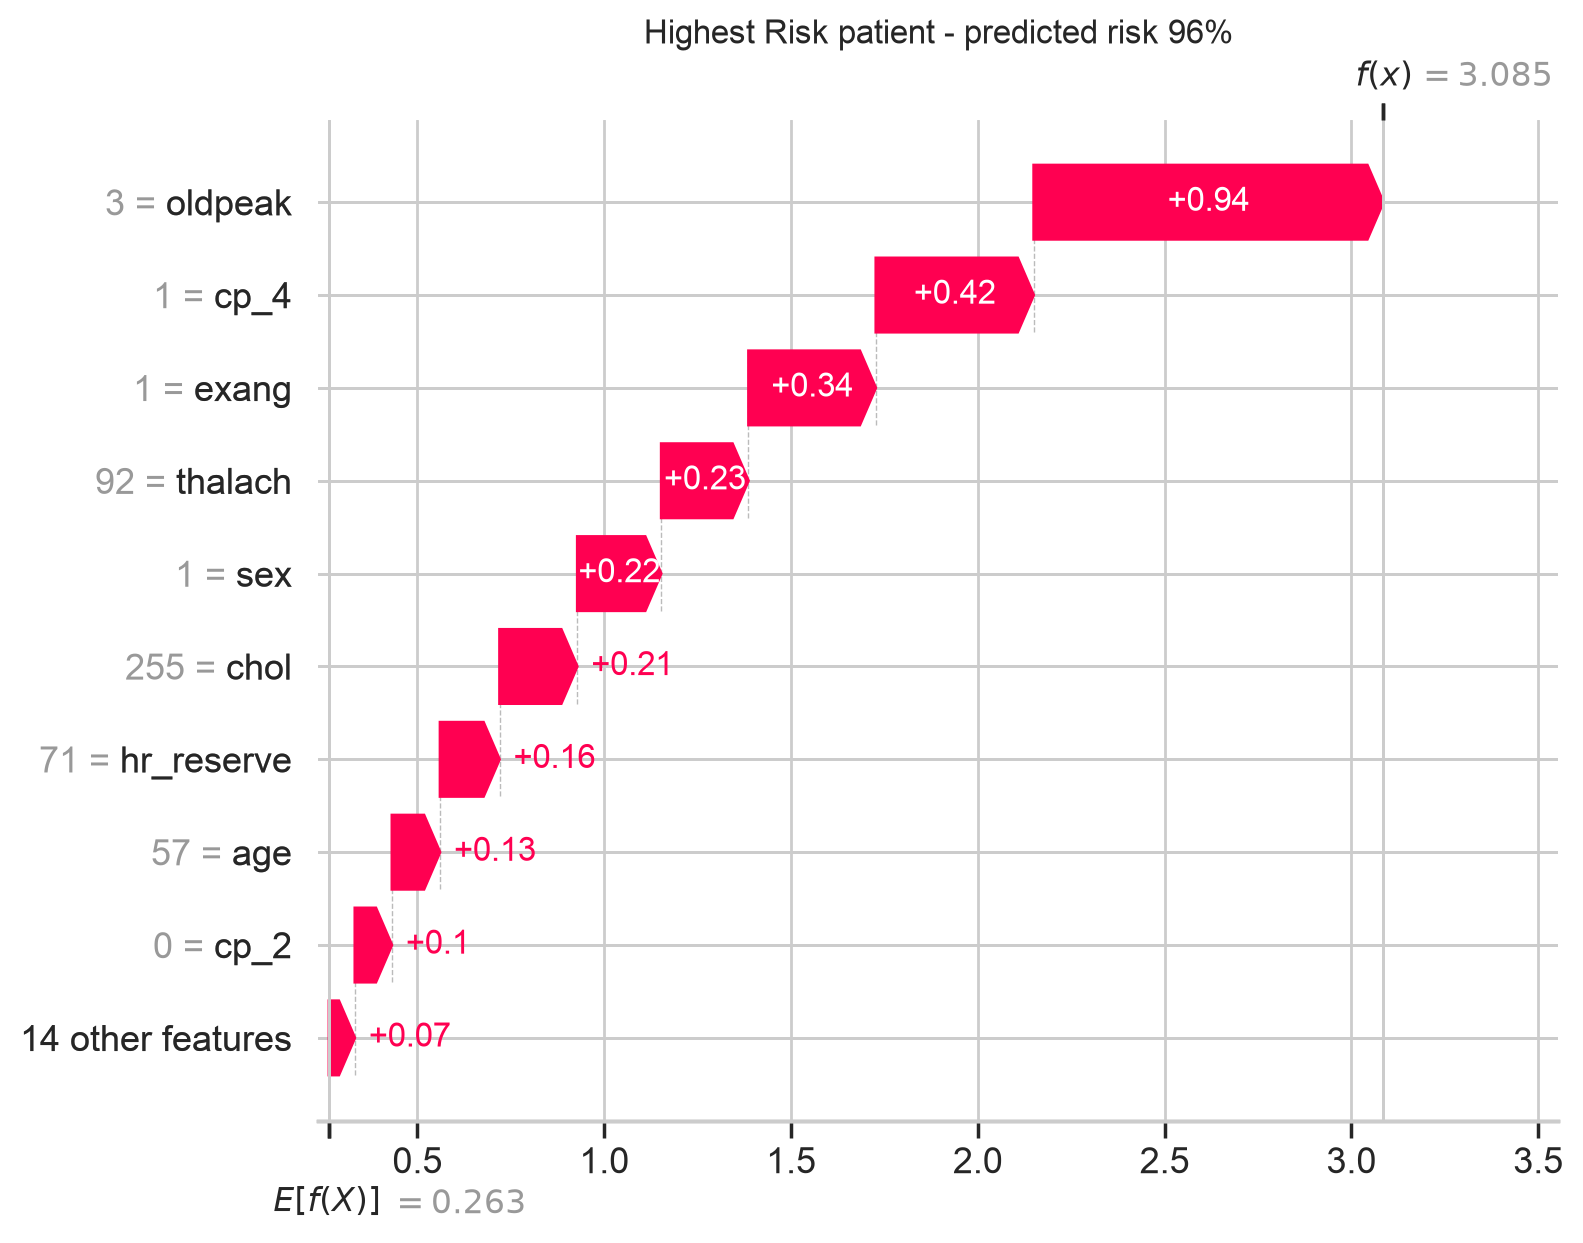

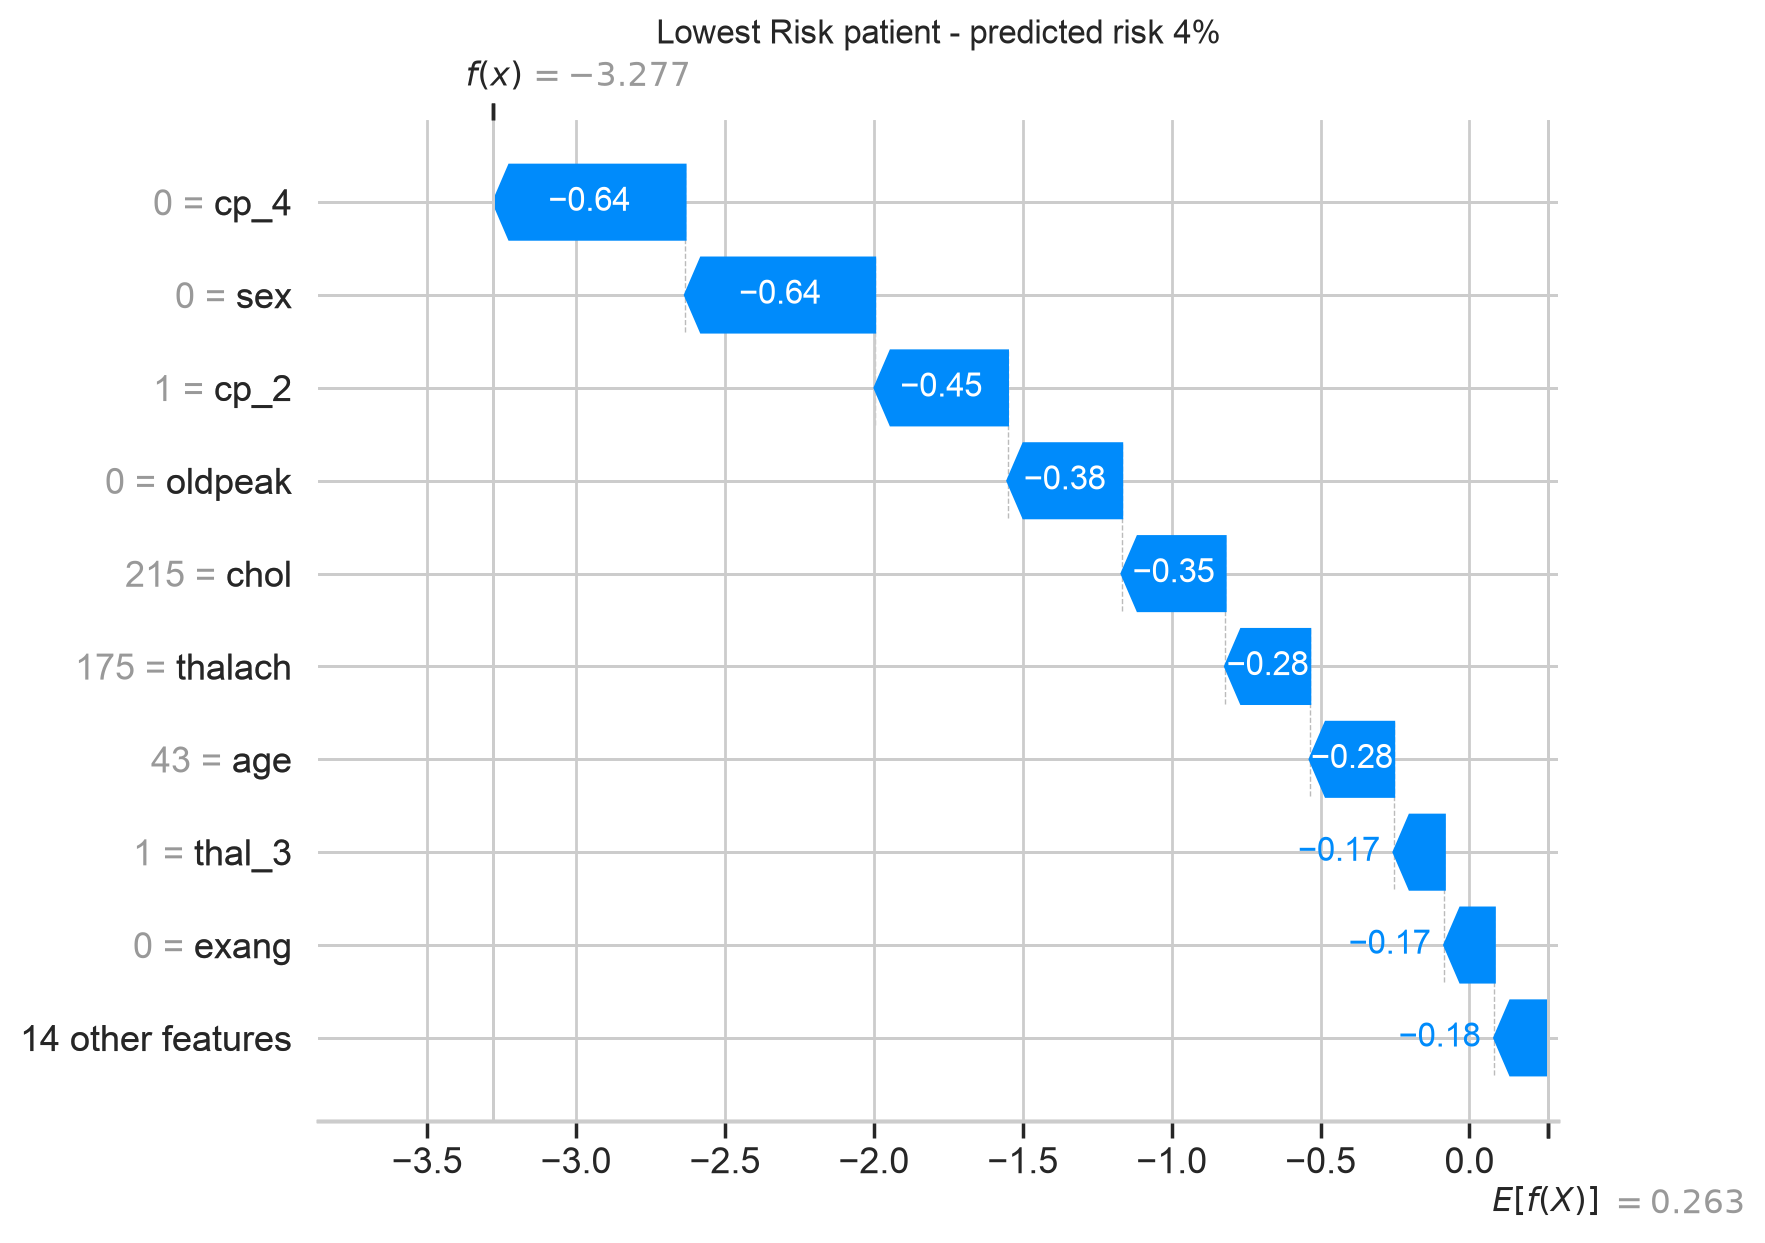

In [11]:
img("10_waterfall_highest_risk.png", 560)
img("10_waterfall_lowest_risk.png", 560)

## 8. Using the model: score one patient with an explanation
This is exactly what the Streamlit app does (`uv run streamlit run app.py`). Edit the values and re-run.

/Users/admin/projects/xai_clinic/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Model risk score: 95% -> tier High** (Gradient Boosting). A model score, not a calibrated probability for any specific hospital. Educational use only.

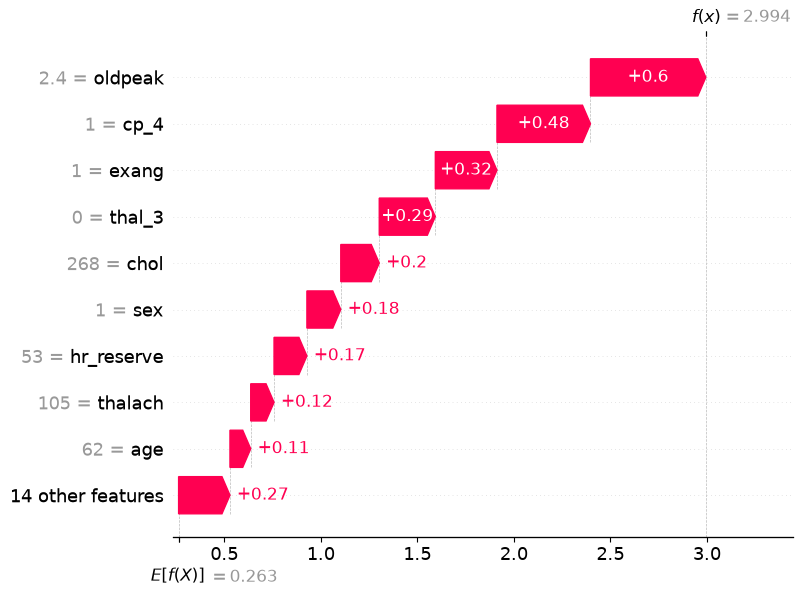

In [12]:
import joblib, shap
from xai_clinic.data_processing import engineer
from xai_clinic.decision import risk_tier
from xai_clinic.explain import explain

art = joblib.load(FIG / "model_artifact.joblib")
patient = dict(age=62, sex=1, cp=4, trestbps=140, chol=268, fbs=0, restecg=2,
               thalach=105, exang=1, oldpeak=2.4, slope=2, thal=7)       # slope / thal may be np.nan if unknown
Xp = engineer(pd.DataFrame([patient])).reindex(columns=art["input_columns"])
prob = float(art["pipeline"].predict_proba(Xp)[0, 1])
say(f"**Model risk score: {prob:.0%} -> tier {risk_tier(prob)}** ({art['model_name']}). "
    "A model score, not a calibrated probability for any specific hospital. Educational use only.")
sv, _ = explain(art["pipeline"], art["background"], Xp)
shap.plots.waterfall(sv[0], max_display=10, show=False)
plt.show()

## 9. Limitations and next steps
- 1980s data from four hospitals, mostly male; women are almost absent from two sites. Labels are *angiographic disease at testing*, not future events.
- Probabilities drift between hospitals; deploying anywhere needs local recalibration (section 4).
- The cost ratio and deployment prevalence in section 6 are **assumptions**, not measurements.
- **Next:** a hospital-adjusted model (hospital as a fixed effect during training, neutralised at prediction time), external validation on a modern dataset, and calibration checked per subgroup.

*Not a medical device.*

In [13]:
p = FIG / "RESULTS_SUMMARY.md"
if p.exists(): display(Markdown(p.read_text(encoding="utf-8")))

# Results summary (auto-generated)

## Research-style resume bullet
Built a validated, explainable heart-disease detection pipeline on 918 patients from four hospitals; nested CV found no statistically significant difference between logistic regression (0.88), Random Forest (0.88) and Gradient Boosting (0.88) AUC; leave-one-hospital-out AUC ranged 0.71-0.85; SHAP importances agreed across models (Spearman 0.76-0.92).

## Industry-style resume bullet
Built an interactive Streamlit risk-scoring demo for heart-disease detection with risk tiers, per-patient SHAP explanations and a cost-based decision threshold (assumed 5:1 miss-to-false-alarm cost; at an assumed 10% prevalence it flags 157 per 1,000 and misses 30.4 of 100 cases); audited subgroup and cross-hospital performance, documented calibration drift and a local recalibration fix (Brier -8% on average); added unit tests, CI and a model card.

Check every claim against the tables in MODEL_CARD.md before using these.
